In [6]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import collections
import random
import time
import json
import pickle
from PIL import Image
from tqdm import tqdm

# Keras güncellemelerinden kaynaklanan hatayı bu şekilde çözüyoruz:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model

print("TensorFlow Versiyonu:", tf.__version__)
print("GPU Mevcut mu?:", "Evet" if tf.config.list_physical_devices('GPU') else "Hayır (Lütfen Ayarlardan GPU'yu aç!)")

# --- PROJE PARAMETRELERİ ---
EPOCHS = 50           # Hedeflediğin yüksek başarı için
BATCH_SIZE = 64
BUFFER_SIZE = 1000
EMBEDDING_DIM = 256
UNITS = 512
VOCAB_SIZE = 5000
MAX_LENGTH = 50

TensorFlow Versiyonu: 2.20.0
GPU Mevcut mu?: Evet


In [7]:
# Veri setini indir (Eğer daha önce inmediyse)
if not os.path.exists('Flickr8k_Dataset.zip'):
    !wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_Dataset.zip
    !wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_text.zip
    !unzip -q Flickr8k_Dataset.zip
    !unzip -q Flickr8k_text.zip -d Flickr8k_text
    print("Veri seti başarıyla hazırlandı.")
else:
    print("Veri seti zaten mevcut.")

Veri seti başarıyla hazırlandı.


In [8]:
def load_and_clean_captions(filename):
    with open(filename, 'r') as f:
        lines = f.readlines()

    clean_captions = []
    img_names = []

    for line in lines:
        parts = line.split('\t')
        if len(parts) < 2: continue

        img_name = parts[0].split('#')[0]
        # Temizleme: Küçük harf, noktalama kaldırma, başlangıç/bitiş etiketleri
        cap = parts[1].strip().lower()
        cap = ''.join([char for char in cap if char.isalpha() or char == ' '])
        cap = f"startseq {cap} endseq"

        clean_captions.append(cap)
        img_names.append(img_name)

    return pd.DataFrame({'image': img_names, 'caption': clean_captions})

df = load_and_clean_captions('Flickr8k_text/Flickr8k.token.txt')

# ANALİZ: En çok kullanılan kelimeleri görelim (Proje raporuna eklenebilir)
all_words = " ".join(df['caption']).split()
word_counts = collections.Counter(all_words)
print("En çok geçen 10 kelime:", word_counts.most_common(10))

df.head() # İlk 5 satırı görerek kontrol edelim

En çok geçen 10 kelime: [('a', 62989), ('startseq', 40460), ('endseq', 40460), ('in', 18975), ('the', 18419), ('on', 10744), ('is', 9345), ('and', 8852), ('dog', 8136), ('with', 7765)]


,image,caption
0,1000268201_693b08cb0e.jpg,startseq a child in a pink dress is climbing u...
1,1000268201_693b08cb0e.jpg,startseq a girl going into a wooden building ...
2,1000268201_693b08cb0e.jpg,startseq a little girl climbing into a wooden ...
3,1000268201_693b08cb0e.jpg,startseq a little girl climbing the stairs to ...
4,1000268201_693b08cb0e.jpg,startseq a little girl in a pink dress going i...


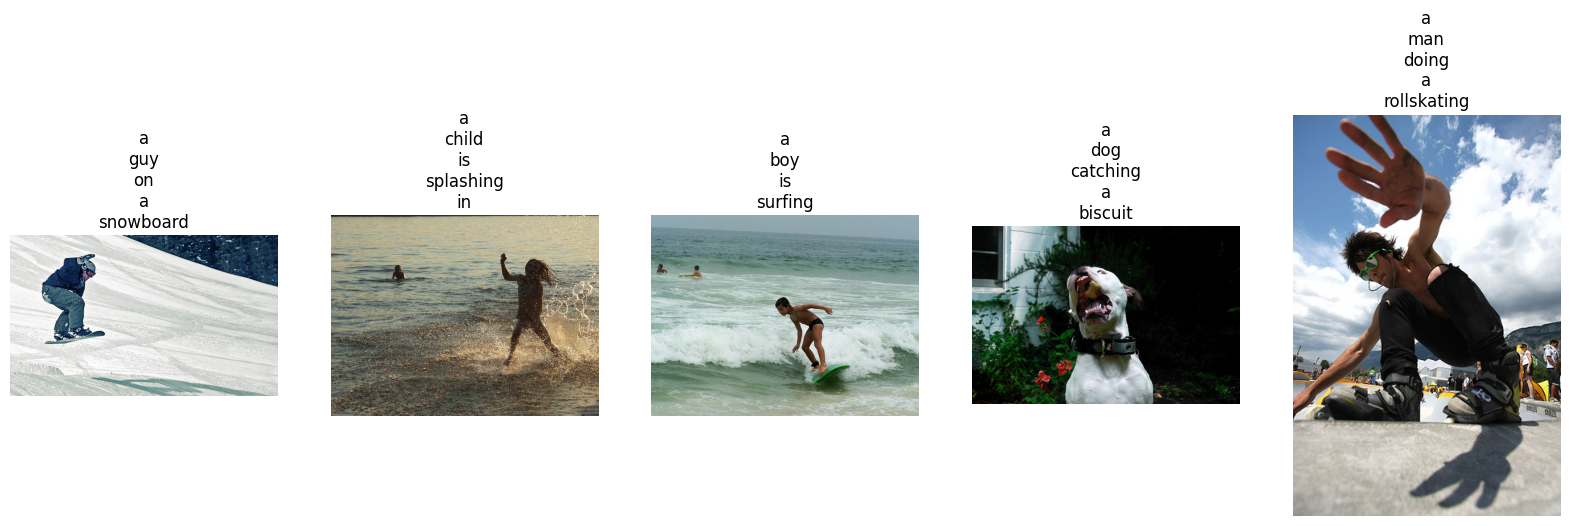

In [9]:
# 4. Hücre: Rastgele Görüntüleri Görselleştirme
def plot_random_images(df, root_path='Flicker8k_Dataset/'):
    plt.figure(figsize=(20, 10))
    random_images = random.sample(list(df['image'].unique()), 5)

    for i, img_name in enumerate(random_images):
        plt.subplot(1, 5, i+1)
        # Resmin tam yolunu kontrol edelim (Klasör yapısına göre ayarlanmalı)
        img_path = os.path.join(root_path, img_name)
        img = Image.open(img_path)
        plt.imshow(img)
        plt.title("\n".join(df[df['image']==img_name]['caption'].values[0].split()[1:-1][:5]))
        plt.axis('off')
    plt.show()

# Resimlerin bulunduğu ana klasör adını kontrol et (Genelde Flicker8k_Dataset olur)
plot_random_images(df)

In [11]:
# Önce doğru klasörü bulalım
import os

# Mevcut dizindeki klasörleri kontrol et
possible_paths = ['Flicker8k_Dataset', 'Flickr8k_Dataset', 'Images', 'flicker8k_dataset']
IMAGE_DIR = None

for p in possible_paths:
    if os.path.exists(p):
        IMAGE_DIR = p
        break

if IMAGE_DIR is None:
    # Eğer yukarıdakiler yoksa, içinde .jpg olan ilk klasörü bul
    for root, dirs, files in os.walk('.'):
        for file in files:
            if file.endswith(".jpg"):
                IMAGE_DIR = root
                break
        if IMAGE_DIR: break

print(f"Resimlerin bulunduğu klasör onaylandı: {IMAGE_DIR}")

# Modeli kur
image_model = InceptionV3(weights='imagenet')
feature_extraction_model = Model(image_model.input, image_model.layers[-2].output)

def load_image(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (299, 299))
    img = tf.keras.applications.inception_v3.preprocess_input(img)
    return img, image_path

# Sadece klasörde gerçekten var olan resimleri listeye ekleyelim (Hata almamak için)
all_img_paths = []
found_images = set(os.listdir(IMAGE_DIR))

# DataFrame'deki resimlerden sadece klasörde olanları seç
valid_images = [img for img in df['image'].unique() if img in found_images]
all_img_paths = [os.path.join(IMAGE_DIR, name) for name in valid_images]

print(f"Toplam {len(all_img_paths)} geçerli resim bulundu. Özellik çıkarma başlıyor...")

image_features = {}
img_dataset = tf.data.Dataset.from_tensor_slices(all_img_paths)
img_dataset = img_dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(64)

for img, path in tqdm(img_dataset):
    batch_features = feature_extraction_model(img)
    for bf, p in zip(batch_features, path):
        path_of_img = p.numpy().decode("utf-8")
        image_features[path_of_img] = bf.numpy()

print("\nÖzellik çıkarma başarıyla tamamlandı!")

Resimlerin bulunduğu klasör onaylandı: Flicker8k_Dataset
Toplam 8091 geçerli resim bulundu. Özellik çıkarma başlıyor...


100%|██████████| 127/127 [01:09<00:00,  1.84it/s]


Özellik çıkarma başarıyla tamamlandı!


In [12]:
# 6. Hücre: Tokenizer Hazırlama
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>", filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~ ')
tokenizer.fit_on_texts(df['caption'].values)

# Kelimeleri sayılara çevir ve padding yap (Tüm cümleler aynı uzunlukta olmalı)
train_seqs = tokenizer.texts_to_sequences(df['caption'].values)
cap_vector = pad_sequences(train_seqs, padding='post', maxlen=MAX_LENGTH)

# Sözlüğü kaydedelim (İleride lazım olacak)
with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

print(f"Sözlük Boyutu: {len(tokenizer.word_index)}")

<>:2: SyntaxWarning: invalid escape sequence '\]'
<>:2: SyntaxWarning: invalid escape sequence '\]'
/tmp/ipykernel_548/3659358647.py:2: SyntaxWarning: invalid escape sequence '\]'
  tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>", filters='!"#$%&()*+.,-/:;=?@[\]^_`{|}~ ')


Sözlük Boyutu: 8781


In [13]:
# 7. Hücre: Model Bileşenlerinin Tanımlanması

class BahdanauAttention(tf.keras.Model):
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        # features shape: (batch_size, 64, embedding_dim)
        # hidden shape: (batch_size, hidden_size)
        hidden_with_time_axis = tf.expand_dims(hidden, 1)

        # Attention skorunu hesaplıyoruz
        score = tf.nn.tanh(self.W1(features) + self.W2(hidden_with_time_axis))
        attention_weights = tf.nn.softmax(self.V(score), axis=1)

        # Resim bölgelerini ağırlıklandırıyoruz
        context_vector = attention_weights * features
        context_vector = tf.reduce_sum(context_vector, axis=1)
        return context_vector, attention_weights

class CNN_Encoder(tf.keras.Model):
    def __init__(self, embedding_dim):
        super(CNN_Encoder, self).__init__()
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        x = self.fc(x)
        x = tf.nn.relu(x)
        return x

class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size):
        super(RNN_Decoder, self).__init__()
        self.units = units
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(self.units, return_sequences=True, return_state=True,
                                   recurrent_initializer='glorot_uniform')
        self.fc1 = tf.keras.layers.Dense(self.units)
        self.fc2 = tf.keras.layers.Dense(vocab_size)
        self.attention = BahdanauAttention(self.units)

    def call(self, x, features, hidden):
        context_vector, attention_weights = self.attention(features, hidden)
        x = self.embedding(x)
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)
        output, state = self.gru(x)
        x = self.fc1(output)
        x = tf.reshape(x, (-1, x.shape[2]))
        x = self.fc2(x)
        return x, state, attention_weights

In [14]:
# 8. Hücre: Modeli Başlatma
encoder = CNN_Encoder(EMBEDDING_DIM)
decoder = RNN_Decoder(EMBEDDING_DIM, UNITS, VOCAB_SIZE)

optimizer = tf.keras.optimizers.Adam()
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction='none')

def loss_function(real, pred):
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    loss_ = loss_object(real, pred)
    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask
    return tf.reduce_mean(loss_)

In [21]:
# 1. Modeli İnşa Etme (Hatayı önlemek için boş veriyle bir kez çalıştırıyoruz)
sample_img_batch = tf.zeros((BATCH_SIZE, 2048))
sample_cap_batch = tf.zeros((BATCH_SIZE, MAX_LENGTH))

# Modeli bir kez manuel çalıştırarak değişkenleri oluşturuyoruz
with tf.GradientTape() as tape:
    features = encoder(sample_img_batch)
    hidden = tf.zeros((BATCH_SIZE, UNITS))
    dec_input = tf.expand_dims([tokenizer.word_index['startseq']] * BATCH_SIZE, 1)
    predictions, hidden, _ = decoder(dec_input, features, hidden)

print("Model başarıyla inşa edildi. Eğitim başlıyor...")

# 2. Güncellenmiş Eğitim Fonksiyonu (Dekoratörü kaldırdık, daha stabil çalışır)
def train_step_optimized(img_tensor, target):
    loss = 0
    hidden = tf.zeros((target.shape[0], UNITS))
    dec_input = tf.expand_dims([tokenizer.word_index['startseq']] * target.shape[0], 1)

    with tf.GradientTape() as tape:
        features = encoder(img_tensor)
        for i in range(1, target.shape[1]):
            predictions, hidden, _ = decoder(dec_input, features, hidden)
            loss += loss_function(target[:, i], predictions)
            dec_input = tf.expand_dims(target[:, i], 1)

    total_loss = (loss / int(target.shape[1]))
    trainable_variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, trainable_variables)
    optimizer.apply_gradients(zip(gradients, trainable_variables))
    return total_loss

# 3. Eğitim Döngüsü
loss_history = []
num_steps = len(X_img) // BATCH_SIZE

for epoch in range(EPOCHS):
    start = time.time()
    total_loss = 0

    for (batch, (img_tensor, target)) in enumerate(dataset):
        batch_loss = train_step_optimized(img_tensor, target)
        total_loss += batch_loss

        if batch % 100 == 0:
            print(f'Epoch {epoch+1} Batch {batch} Loss {batch_loss.numpy():.4f}')

    epoch_loss = total_loss / num_steps
    loss_history.append(epoch_loss)

    print(f'*** Epoch {epoch+1} Bitti. Loss: {epoch_loss:.4f} - Süre: {time.time()-start:.1f} sn ***')

# --- BAŞARI ANALİZİ GRAFİĞİ ---
plt.figure(figsize=(10, 6))
plt.plot(loss_history, color='green', marker='o', label='Loss (Hata)')
plt.title('Image Captioning Proje Başarı Grafiği', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss Değeri')
plt.legend()
plt.grid(True)
plt.show()

Model başarıyla inşa edildi. Eğitim başlıyor...
Epoch 1 Batch 0 Loss 1.9534
Epoch 1 Batch 100 Loss 1.0013
Epoch 1 Batch 200 Loss 0.9788
Epoch 1 Batch 300 Loss 0.9892
Epoch 1 Batch 400 Loss 0.9590
Epoch 1 Batch 500 Loss 0.8896
Epoch 1 Batch 600 Loss 0.8688
*** Epoch 1 Bitti. Loss: 0.9782 - Süre: 1273.0 sn ***
Epoch 2 Batch 0 Loss 0.9411
Epoch 2 Batch 100 Loss 0.7889
Epoch 2 Batch 200 Loss 0.8030
Epoch 2 Batch 300 Loss 0.8000
Epoch 2 Batch 400 Loss 0.8296
Epoch 2 Batch 500 Loss 0.8336
Epoch 2 Batch 600 Loss 0.8074
*** Epoch 2 Bitti. Loss: 0.8328 - Süre: 1288.7 sn ***
Epoch 3 Batch 0 Loss 0.8380
Epoch 3 Batch 100 Loss 0.7996
Epoch 3 Batch 200 Loss 0.7786
Epoch 3 Batch 300 Loss 0.8342
Epoch 3 Batch 400 Loss 0.8430
Epoch 3 Batch 500 Loss 0.8082
Epoch 3 Batch 600 Loss 0.7737
*** Epoch 3 Bitti. Loss: 0.7918 - Süre: 1294.4 sn ***
Epoch 4 Batch 0 Loss 0.8717
Epoch 4 Batch 100 Loss 0.7808
Epoch 4 Batch 200 Loss 0.7381
Epoch 4 Batch 300 Loss 0.8106
Epoch 4 Batch 400 Loss 0.7231
Epoch 4 Batch 500 

KeyboardInterrupt: 

Model kaydedildi!


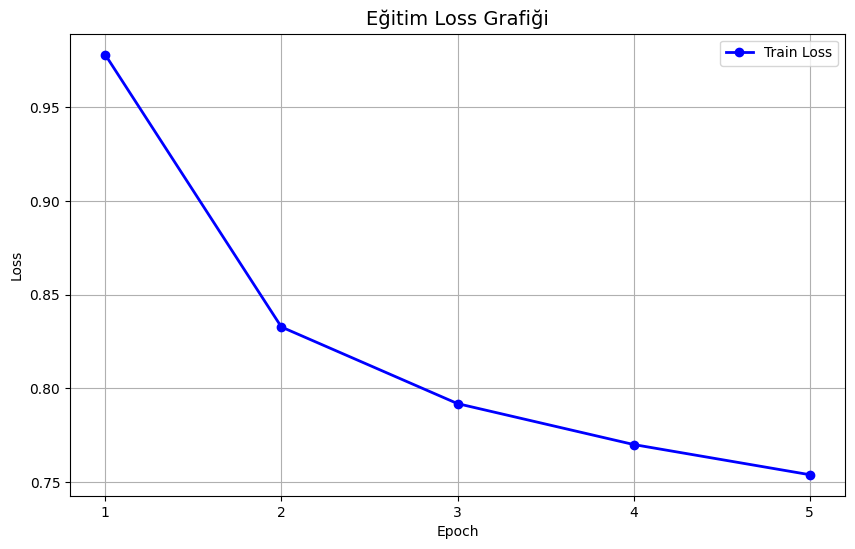

In [23]:
# MODELİ KAYDET
encoder.save_weights('/content/encoder.weights.h5')
decoder.save_weights('/content/decoder.weights.h5')

import pickle
with open('/content/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

print("Model kaydedildi!")

# LOSS GRAFİĞİ
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(loss_history, color='blue', marker='o', linewidth=2, label='Train Loss')
plt.title('Eğitim Loss Grafiği', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(len(loss_history)), range(1, len(loss_history)+1))
plt.legend()
plt.grid(True)
plt.savefig('/content/loss_grafigi.png')
plt.show()